# Diagnosing & fixing vaso magnitude saturation in the CQL actor

From the vaso-reward sweep (c=0): `v_raw_mean ≈ -12.7` at every clinician-vaso state (sigmoid' ≈ 3e-6), identical whether the
own critic favours vaso (55% of states) or not; gate p ≈ 0.017 everywhere. The actor's vaso output is a state-independent constant.

Mechanism: the vaso mean-saturation regulariser is gate-weighted (≈ p ≈ 0.017 → off), and the magnitude head only gets Q-gradient on
fired samples (~1.7%), where the sigmoid is flat. Fix: un-gated one-sided hinge `vaso_mean_floor_scale * relu(vaso_mean_floor - v_raw_mean)^2`
in `cql_with_logprobs.py`.

1. Derive `vaso_mean_floor` from clinician data → training config
2. How widespread is saturation in existing models?
3. Does each actor follow its own critic?
4. After retraining with the floor: repeat 2–3 and compare behaviour

VAL set throughout.

In [1]:
import sys
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.evaluate_vaso_reward_sweep as vrs
import src.rl.diagnose_vaso_saturation as dvs

pd.set_option("display.float_format", "{:.4g}".format)

# paths

In [5]:
basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed"
cql_model_dir =  "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only"

vaso_sweep_dir = os.path.join(cql_model_dir, "vaso_reward_coefficient_sweep")
alpha_sweep_dir = os.path.join(cql_model_dir, "cql_alpha_sweep")                      # same as the vaso analysis baseline
final_seeds_dir = os.path.join(cql_model_dir, "fixed_alpha")  # <-- CHECK: final 5-seed folder
floor_runs_dir = os.path.join(cql_model_dir, "vaso_mean_floor")  # <-- new runs go here

SAVE_DIR = os.path.join(cql_model_dir, "with_actions", "health_score_change_only", "vaso_saturation_analysis")
os.makedirs(SAVE_DIR, exist_ok=True)

In [6]:
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    state_dim = json.load(f)['hyperparameters']['d_model']
print(f"state_dim = {state_dim}")

Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7/unknown_cx3-20-1_20260821-202508_49e52257
state_dim = 128


# Load models

In [7]:
# vaso sweep (for cql_alpha + a few coefficients to compare)
vaso_models_by_coef, vaso_table = vrs.load_vaso_sweep_models(vaso_sweep_dir, state_dim, baseline_dir=None)
target_alpha = float(vaso_table["cql_alpha"].dropna().unique()[0])

models = {}
models["baseline c=0 (alpha sweep)"] = dvs.load_matching_alpha_run(alpha_sweep_dir, target_alpha, state_dim)
for c in [0.1, 0.2, 0.25, 1.0]:
    if c in vaso_models_by_coef:
        models[f"vaso c={c:g}"] = vaso_models_by_coef[c][0]

final_models = dvs.load_models(final_seeds_dir, state_dim, label_fmt="final seed {seed}")
models.update(final_models)
print(list(models.keys()))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260929_173033/unknown_cx3-20-0_20260929-192442_9a084f90
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260929_173033/unknown_cx3-20-0_20260929-182751_ed630447
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparame

# Load data

In [9]:
_, _, data_config_manager, data_hyperparams = models["baseline c=0 (alpha sweep)"]
data_hyperparams = dict(data_hyperparams)
data_hyperparams['add_reward_to_vaso_dosing'] = False

data_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    data_config_manager.get_data_dir, 'cohorts', 'icu_units', f"{data_config_manager.unit.lower()}_stay_ids.csv")
data_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    data_config_manager.get_data_dir, 'cohorts', 'age', 'pediatric_stay_ids.csv')

# config_manager expects a seed_mode attribute, not present in some of the older config managers, so we add it here
if not hasattr(data_config_manager, "seed_mode"):
    data_config_manager.seed_mode = "single_seed"

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(data_config_manager, data_hyperparams)
training_actions = processors['train'].rl_dataset["actions"]

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


# 1. Choose the floor
Floor = logit(smallest real clinician vaso dose) − 1 raw-space SD: below every dose clinicians actually give, so the hinge
only stops drift into the flat sigmoid tail. **Copy the printed values into the training config.**

In [13]:
for kw in [dict(method="percentile", pct=1.0), dict(method="percentile", pct=0.1),
           dict(method="sd", n_sd=3.0), dict(method="min_sd", n_sd=1.0)]:
    print("-" * 70); dvs.recommend_vaso_floor(training_actions, **kw)

floor_info = dvs.recommend_vaso_floor(training_actions, method="percentile", pct=1.0)
VASO_FLOOR = floor_info["vaso_mean_floor"]

----------------------------------------------------------------------
  method                                 percentile (pct=1.0)
  n_nonzero_clinician                    37855
  min_nonzero_dose                       0.006045
  min_dose_z_score                       -6.362
  raw_mean                               -1.067
  raw_std                                0.6342
  raw_p0.1 / p1 / p5                     -4.427 / -2.939 / -1.848
  vaso_mean_floor                        -2.939
  dose_at_floor                          0.05024
  sigmoid_grad_at_floor                  0.04771
  grad_ratio_floor_vs_clin_mean          0.2506
  frac_clinician_doses_below_floor_%     0.8982

  -> set in training config:  'vaso_mean_floor': -2.939,  'vaso_mean_floor_scale': 0.05
----------------------------------------------------------------------
  method                                 percentile (pct=0.1)
  n_nonzero_clinician                    37855
  min_nonzero_dose                       0.006045

# 2. How widespread is the saturation?

In [14]:
sat_df, raw_means = dvs.saturation_table(models, processors['val'], VASO_FLOOR)
sat_df.to_csv(os.path.join(SAVE_DIR, "saturation_table_existing_models_val.csv"))
sat_df

,cql_alpha,vaso_coef,vaso_mean_floor,v_raw_median,v_raw_p10,v_raw_p90,v_raw_sd_across_states,v_raw_median_clin_vaso,frac_below_floor_%,frac_saturated_%,...,gate_p_sd_across_states,gate_p_clin_vaso,gate_auroc_clin_vaso,vaso_reg_weight_mean,v_std_median,v_std_at_floor_%,v_std_at_ceiling_%,vaso_fire_%,fluid_fire_%,fluid_raw_median
baseline c=0 (alpha sweep),0.022,0,NaN,-13.43,-17.29,-11.79,2.527,-12.8,100,100,...,0.004853,0.01558,0.4256,0.01685,0.6021,0,0.4626,0,100,-0.2998
vaso c=0.1,0.022,0.1,NaN,-11.62,-17.05,-9.402,3.222,-10,100,99.94,...,0.01019,0.01891,0.6668,0.01344,0.8994,0,4.719,0,100,-0.3397
vaso c=0.2,0.022,0.2,NaN,-9.253,-13.62,-7.425,2.847,-7.771,100,74.01,...,0.01556,0.04342,0.8005,0.02759,0.6683,0.02218,0.005546,0,100,0.09695
vaso c=0.25,0.022,0.25,NaN,-9.136,-14.95,-1.583,5.042,-1.527,79.24,57.8,...,0.4207,0.8034,0.8722,0.03106,0.1353,100,0,27.32,100,0.006098
vaso c=1,0.022,1,NaN,-13.25,-21.26,-0.8718,7.961,-0.8128,71.34,62.66,...,0.009433,0.9975,0.8375,0.008339,1.365,29.47,35.32,39.76,100,0.1812
final seed 3,0.022,0,NaN,-15.56,-20.15,-14.14,2.894,-15.25,100,100,...,0.005049,0.01106,0.426,0.01227,0.6609,0,0.355,0,100,-0.254
final seed 1,0.022,0,NaN,-12.7,-18.48,-10.96,3.502,-11.54,100,100,...,0.005236,0.01385,0.692,0.01064,0.5406,0,0,0,100,-0.04943
final seed 2,0.022,0,NaN,-12.59,-16.92,-11.1,3.019,-11.99,100,100,...,0.004411,0.007349,0.3852,0.00901,0.6474,0,2.392,0,100,-0.2539
final seed 4,0.022,0,NaN,-13.32,-19.83,-2.427,6.277,-3.466,87.81,74.01,...,0.2417,0.9678,0.8145,0.1308,2.718,7.522,53.17,30.13,100,0.08233
final seed 0,0.022,0,NaN,-12.83,-18.46,-10.82,3.559,-11.68,100,100,...,0.006046,0.01596,0.6639,0.01282,0.5591,0,0.3672,0,100,-0.04644


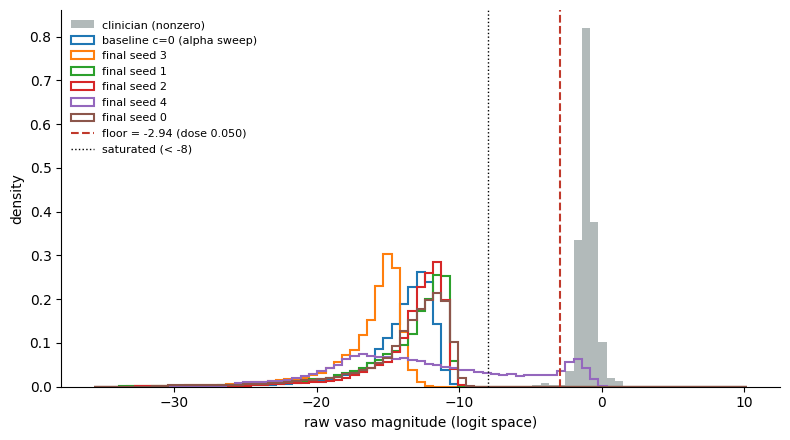

In [15]:
fig = dvs.plot_clinician_vaso_raw(
    training_actions, VASO_FLOOR,
    model_raw_means={k: raw_means[k] for k in raw_means if k.startswith("final") or k.startswith("baseline")},
    save_path=os.path.join(SAVE_DIR, "vaso_raw_mean_vs_clinician_existing.png"),
)

# 3. Does each actor follow its own critic?
At clinician-vaso states. A working actor: gate p / raw mean higher where dQ > 0 (AUROC > 0.5, Spearman > 0).
A saturated actor: identical outputs in both groups.

In [16]:
gvc_df, gvc_states = dvs.gate_vs_critic_table(models, processors['val'])
gvc_df.to_csv(os.path.join(SAVE_DIR, "gate_vs_critic_existing_models_val.csv"))
gvc_df

,n_clin_vaso,frac_dq>0_%,dq_mean_HS,gate_p_median_dq>0,gate_p_median_dq<=0,v_raw_median_dq>0,v_raw_median_dq<=0,auroc_gate_p_vs_dq>0,spearman_gate_p_dq,spearman_v_raw_dq
baseline c=0 (alpha sweep),7484,55.46,-0.04661,0.01682,0.01658,-12.7,-12.89,0.5094,-0.01774,0.06991
vaso c=0.1,7484,68.73,-0.0002991,0.01879,0.01882,-9.998,-10.01,0.5001,-0.06011,0.04132
vaso c=0.2,7484,72.22,0.02467,0.03599,0.03227,-7.737,-7.867,0.5819,0.1909,0.1827
vaso c=0.25,7484,54.28,-0.0274,0.9999,0.9931,-1.152,-2.231,0.7106,0.4379,0.4643
vaso c=1,7484,69.83,0.06176,1,0.9992,-0.6269,-1.866,0.8128,0.6625,0.7049
final seed 3,7484,59.22,-0.01567,0.01213,0.009988,-15.21,-15.31,0.5561,0.09524,0.08974
final seed 1,7484,65.11,0.0129,0.014,0.01381,-11.48,-11.67,0.533,-0.05437,0.05422
final seed 2,7484,60.07,-0.03223,0.005598,0.008002,-12.03,-11.93,0.4053,-0.2082,-0.03075
final seed 4,7484,39.66,-0.05672,1,0.9988,-2.022,-4.976,0.6699,0.3511,0.3378
final seed 0,7484,64.43,-0.001095,0.01568,0.01703,-11.46,-12.16,0.4496,-0.1353,0.2632


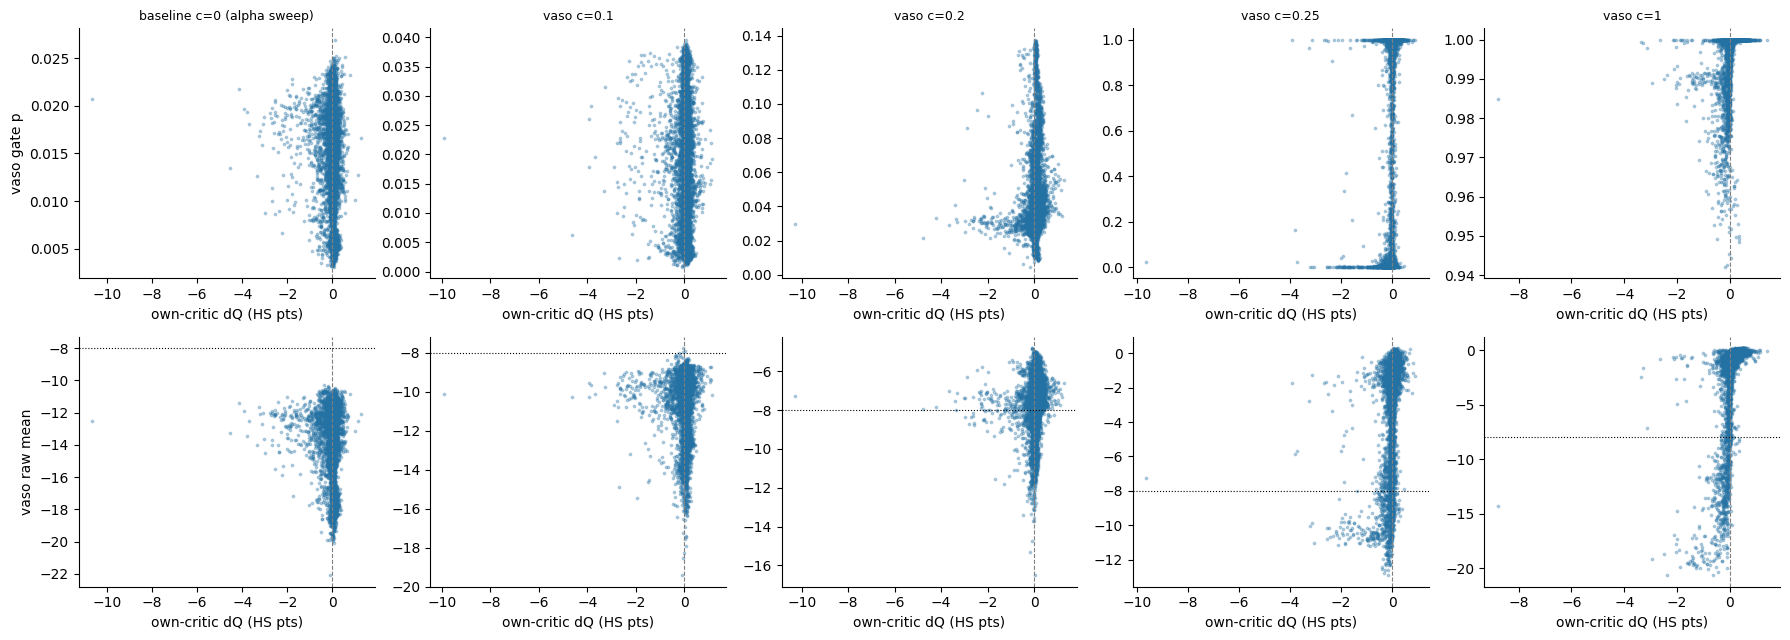

In [17]:
fig = dvs.plot_gate_vs_critic(
    gvc_states, labels=[k for k in gvc_states if not k.startswith("final")][:5],
    save_path=os.path.join(SAVE_DIR, "gate_vs_critic_scatter_existing.png"),
)

# STOP: retrain with the floor
Single-seed sanity check first (c=0, same cql_alpha, seed 42, `vaso_mean_floor` from section 1) into `floor_runs_dir`.
In the training log, confirm `v_mean_floor_penalty` goes to ~0 early and stays there.

# 4. Floor runs: repeat diagnostics and compare

In [18]:
floor_models = dvs.load_models(floor_runs_dir, state_dim, label_fmt="floor seed {seed}, c={coef}")
for k, m in floor_models.items():
    print(k, "vaso_mean_floor =", m[3].get("vaso_mean_floor"), " cql_alpha =", m[3].get("cql_alpha"))

compare = {"baseline c=0 (alpha sweep)": models["baseline c=0 (alpha sweep)"], **floor_models}

FileNotFoundError: [Errno 2] No such file or directory: '/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor'

In [ ]:
sat_floor_df, raw_means_floor = dvs.saturation_table(compare, processors['val'], VASO_FLOOR)
sat_floor_df.to_csv(os.path.join(SAVE_DIR, "saturation_table_floor_runs_val.csv"))
sat_floor_df

In [ ]:
fig = dvs.plot_clinician_vaso_raw(training_actions, VASO_FLOOR, model_raw_means=raw_means_floor,
                                  save_path=os.path.join(SAVE_DIR, "vaso_raw_mean_vs_clinician_floor.png"))

In [ ]:
gvc_floor_df, gvc_floor_states = dvs.gate_vs_critic_table(compare, processors['val'])
gvc_floor_df.to_csv(os.path.join(SAVE_DIR, "gate_vs_critic_floor_runs_val.csv"))
display(gvc_floor_df)
fig = dvs.plot_gate_vs_critic(gvc_floor_states, save_path=os.path.join(SAVE_DIR, "gate_vs_critic_scatter_floor.png"))

## Behaviour: fire rates, specificity, fluid off-target, SARSA advantage, occupancy

In [ ]:
basic_q_health_score_models = []
for model_dir in etm.get_model_dirs(os.path.join(basic_q_dir, "health_score_change_only")):
    critic, cm, hp = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((critic, cm, hp))

train_hs, _ = vrs.per_state_health_score(processors['train'])
val_hs, _ = vrs.per_state_health_score(processors['val'])
sev_edges = vrs.severity_edges_from_train(train_hs, n_bins=10)
clin_ref_val = vrs.clinician_reference(processors['val'], val_hs, sev_edges)

In [ ]:
results_floor = dvs.evaluate_models(compare, processors['val'], val_hs, sev_edges, basic_q_health_score_models,
                                    training_actions, train_hs, n_severity_bins_occ=200)
beh_floor_df = vrs.behaviour_table(results_floor, clin_ref_val)
beh_floor_df.to_csv(os.path.join(SAVE_DIR, "behaviour_floor_runs_val.csv"))
beh_floor_df

In [ ]:
fire_sev_df, pen_sev_df = vrs.severity_tables(results_floor, clin_ref_val, sev_edges)
display(fire_sev_df.round(1))
display(pen_sev_df.round(3))

# What to look for
- **Section 2**: `v_raw_sd_across_states ≈ 0` and `frac_saturated_% ≈ 100` ⇒ state-independent, stuck output. Check whether the final 5 seeds share this.
- **Section 3 (existing)**: AUROC ≈ 0.5 / Spearman ≈ 0 ⇒ actor ignores its critic.
- **Section 4 (floor)**: raw mean varies across states and sits above the floor; gate AUROC vs dQ>0 clearly > 0.5; fluid columns unchanged vs baseline.
  If the floor c=0 policy now doses vaso where its critic favours it, the "CQL recommends zero vaso" headline becomes "CQL is near-indifferent; zero vaso was an actor artefact" → confirm with 5 seeds.